# Expedition 001: what does frozen REVE know about EEG artefacts?

**Question.** Without any fine-tuning, do REVE embeddings separate clean EEG from different artefact types?

**Data.** PhysioMotion Artifact (OpenNeuro ds006386): 59-ch EEG, healthy subjects performing artefact tasks, manual annotations.
**Model.** REVE-base (69M params), frozen. Embeddings cached by `extract.py`.
**Probe.** Logistic regression, leave-one-subject-out. Baseline: log band power (5 bands x 59 ch).

Run `poetry run python expeditions/001-reve-artifacts/extract.py --subjects 1-6 --download` first.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, balanced_accuracy_score, f1_score
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from neuro_expeditions import DATA_DIR
from neuro_expeditions.datasets import physiomotion as pm
from neuro_expeditions.models import reve

CACHE = DATA_DIR / "cache" / "001-reve-artifacts"
CLASSES = ["clean_eyes_open", "clean_eyes_closed", "blink", "eye_movement", "muscle", "head_movement"]
COLORS = dict(zip(CLASSES, plt.cm.tab10.colors))
plt.rcParams["figure.dpi"] = 110

## 1. Look at the raw material
A few channels around each kind of annotated event (after REVE preprocessing: avg ref, 0.3 Hz HP, 200 Hz).

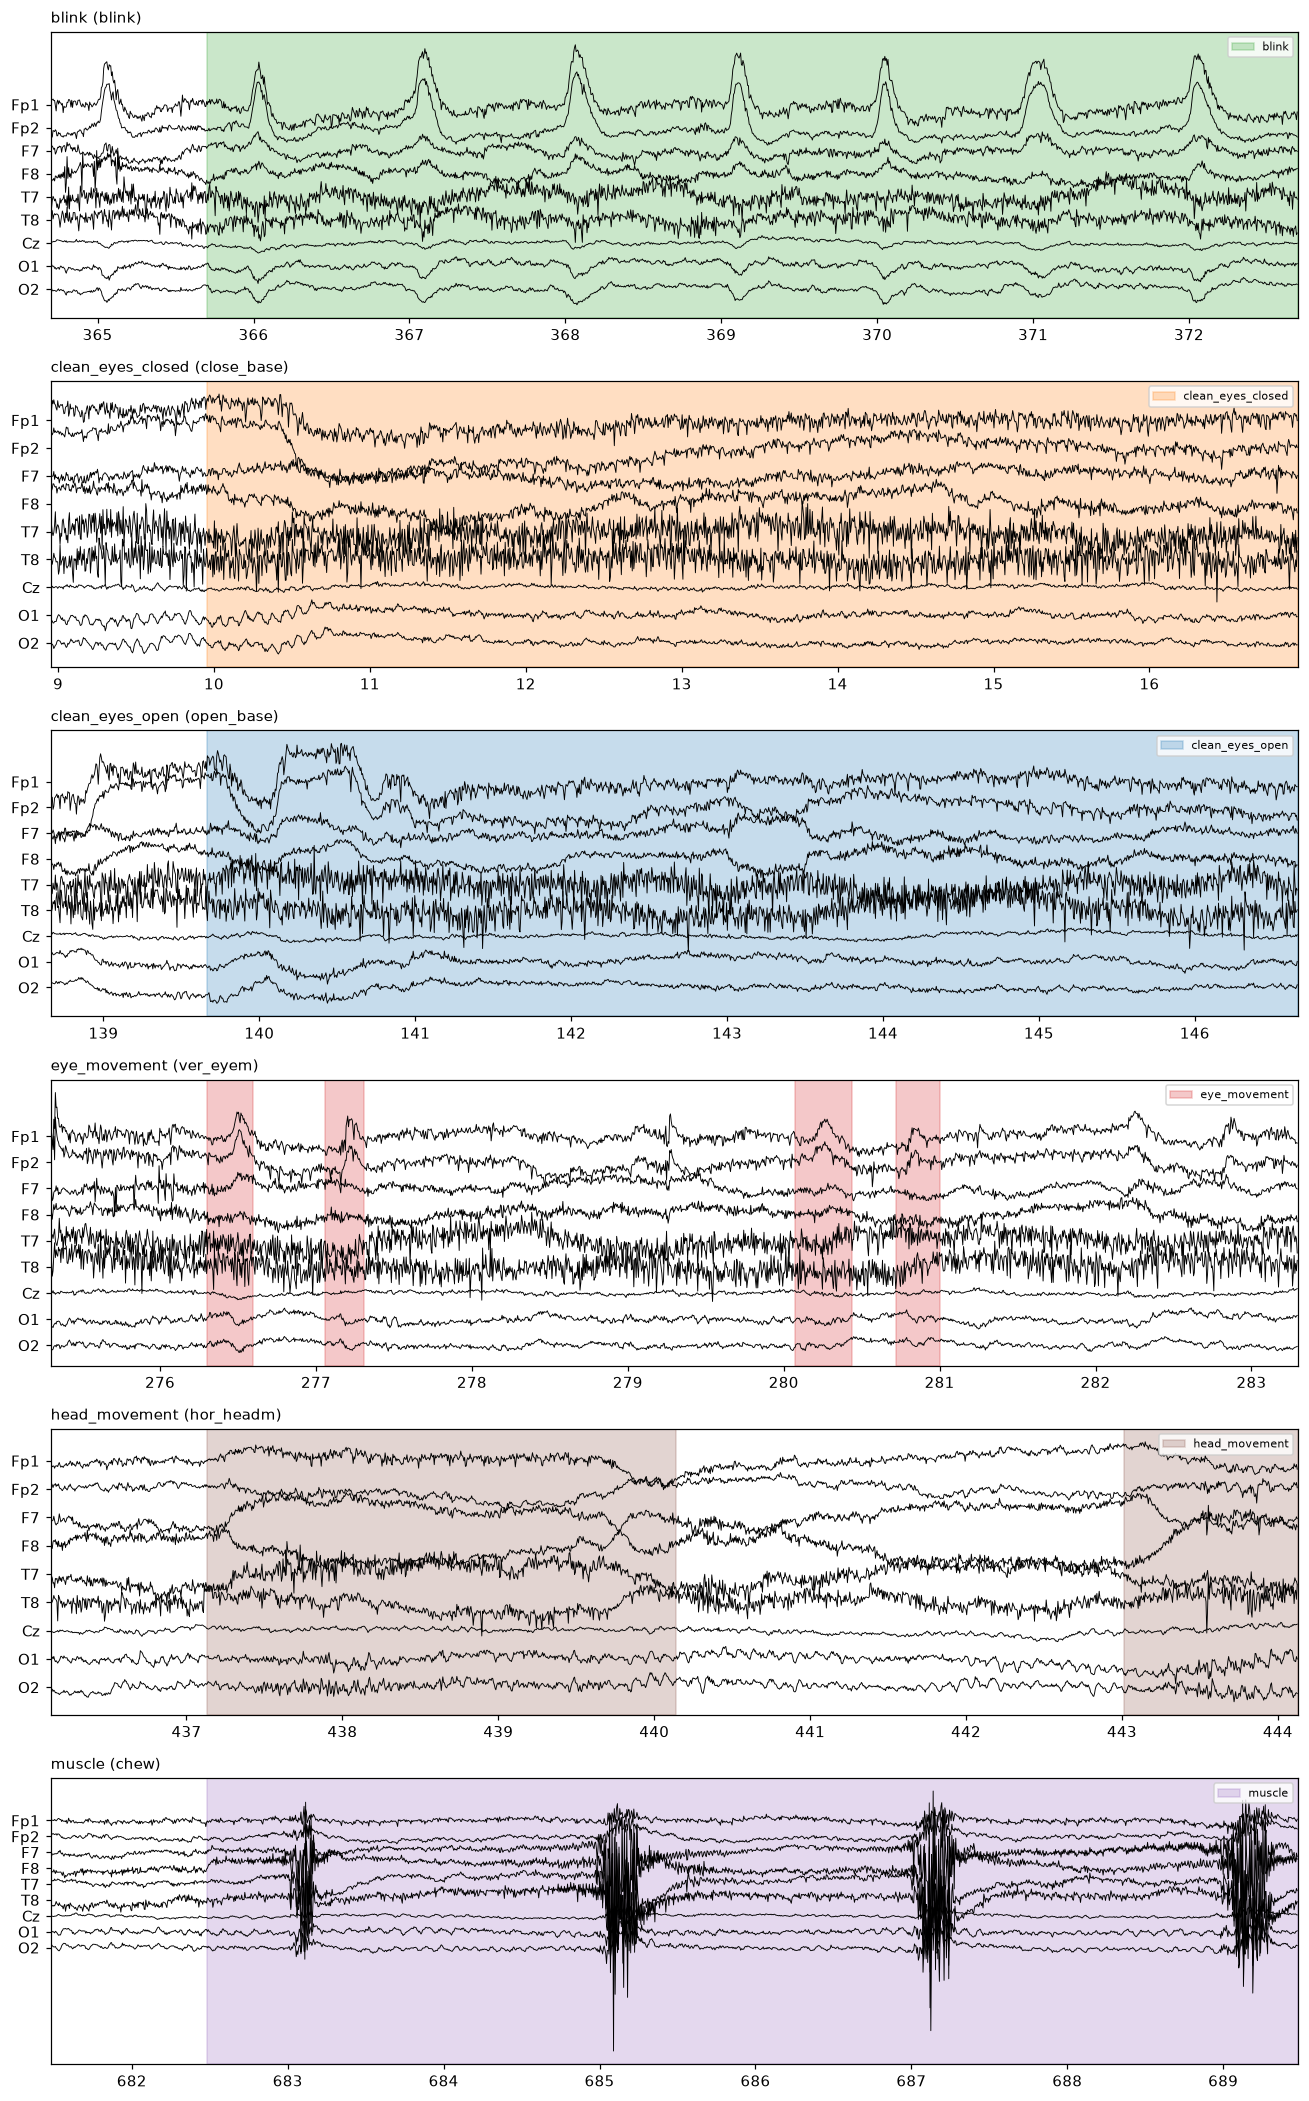

In [2]:
SUB, RUN = 1, 1
raw = reve.preprocess(pm.load_raw(SUB, RUN))
events = pm.load_annotations(SUB, RUN)
SHOW = ["Fp1", "Fp2", "F7", "F8", "T7", "T8", "Cz", "O1", "O2"]

def plot_snippet(raw, t0, dur, events, ax, chans=SHOW, spacing=80):
    sf = raw.info["sfreq"]
    seg = raw.get_data(picks=chans, start=int(t0 * sf), stop=int((t0 + dur) * sf)) * 1e6
    t = t0 + np.arange(seg.shape[1]) / sf
    for i, ch in enumerate(chans):
        ax.plot(t, seg[i] - i * spacing, lw=0.6, color="k")
    for _, e in events[(events.stop > t0) & (events.start < t0 + dur)].iterrows():
        ax.axvspan(max(e.start, t0), min(e.stop, t0 + dur), color=COLORS.get(e.group, "0.8"), alpha=0.25, label=e.group)
    ax.set_yticks(-np.arange(len(chans)) * spacing, chans)
    ax.set_xlim(t0, t0 + dur)
    h, l = ax.get_legend_handles_labels()
    ax.legend(dict(zip(l, h)).values(), dict(zip(l, h)).keys(), loc="upper right", fontsize=7)

examples = events[events.group.isin(CLASSES)].groupby("group").first()
fig, axes = plt.subplots(len(examples), 1, figsize=(12, 3.2 * len(examples)))
for ax, (g, e) in zip(np.atleast_1d(axes), examples.iterrows()):
    plot_snippet(raw, max(e.start - 1, 0), 8, events, ax)
    ax.set_title(f"{g} ({e.label})", loc="left", fontsize=10)
plt.tight_layout()

## 2. Load cached windows
2 s windows, 1 s stride. A window takes a group's label if that group covers >= 50% of it and no other group covers > 10%.

In [3]:
rows = []
for f in sorted(CACHE.glob("sub*_run*.npz")):
    z = np.load(f)
    sub, run = int(f.stem.split("_")[0][3:]), int(f.stem.split("run")[1])
    rows.append(pd.DataFrame({"subject": sub, "run": run, "start": z["starts"], "label": z["labels"],
                              "reve_mean": list(z["reve_mean"]), "reve_attn": list(z["reve_attn"]),
                              "bandpower": list(z["bandpower"])}))
windows = pd.concat(rows, ignore_index=True)
data = windows[windows.label.isin(CLASSES)].reset_index(drop=True)
print(f"{len(windows)} windows total, {len(data)} with a clean single label, subjects: {sorted(data.subject.unique())}")
pd.crosstab(data.label, data.subject, margins=True)

42415 windows total, 11705 with a clean single label, subjects: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


subject,1,2,3,4,5,6,All
label,,,,,,,
blink,355,357,341,350,358,357,2118
clean_eyes_closed,649,391,676,464,0,703,2883
clean_eyes_open,692,704,690,588,714,718,4106
eye_movement,16,55,26,54,12,54,217
head_movement,189,204,98,103,131,215,940
muscle,286,271,220,231,182,251,1441
All,2187,1982,2051,1790,1397,2298,11705


## 3. Linear probe, leave-one-subject-out
Every prediction comes from a model that never saw that subject.

In [4]:
def probe(feature, df=data):
    X, y, g = np.stack(df[feature]), df.label.values, df.subject.values
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1, class_weight="balanced"))
    return cross_val_predict(clf, X, y, groups=g, cv=LeaveOneGroupOut(), n_jobs=-1)

FEATURES = {"REVE (mean pool)": "reve_mean", "REVE (attention pool)": "reve_attn", "Band power baseline": "bandpower"}
preds = {name: probe(col) for name, col in FEATURES.items()}

summary = pd.DataFrame({name: {
    "balanced_acc": balanced_accuracy_score(data.label, p),
    "macro_f1": f1_score(data.label, p, average="macro"),
} for name, p in preds.items()}).T
per_subject = pd.DataFrame({name: data.assign(p=p).groupby("subject").apply(
    lambda d: balanced_accuracy_score(d.label, d.p)) for name, p in preds.items()})
display(summary.round(3)); display(per_subject.round(3))
print(f"chance (balanced) = {1/len(CLASSES):.3f}")

/Users/vinicius.duarte/Library/Caches/pypoetry/virtualenvs/neuro-expeditions-DOJ7ouU9-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/vinicius.duarte/Library/Caches/pypoetry/virtualenvs/neuro-expeditions-DOJ7ouU9-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")
/Users/vinicius.duarte/Library/Caches/pypoetry/virtualenvs/neuro-expeditions-DOJ7ouU9-py3.13/lib/python3.13/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


,balanced_acc,macro_f1
REVE (mean pool),0.703,0.655
REVE (attention pool),0.710,0.658
Band power baseline,0.689,0.621


,REVE (mean pool),REVE (attention pool),Band power baseline
subject,,,
1,0.808,0.762,0.766
2,0.622,0.681,0.477
3,0.604,0.635,0.762
4,0.832,0.812,0.858
5,0.765,0.734,0.772
6,0.642,0.649,0.609


chance (balanced) = 0.167


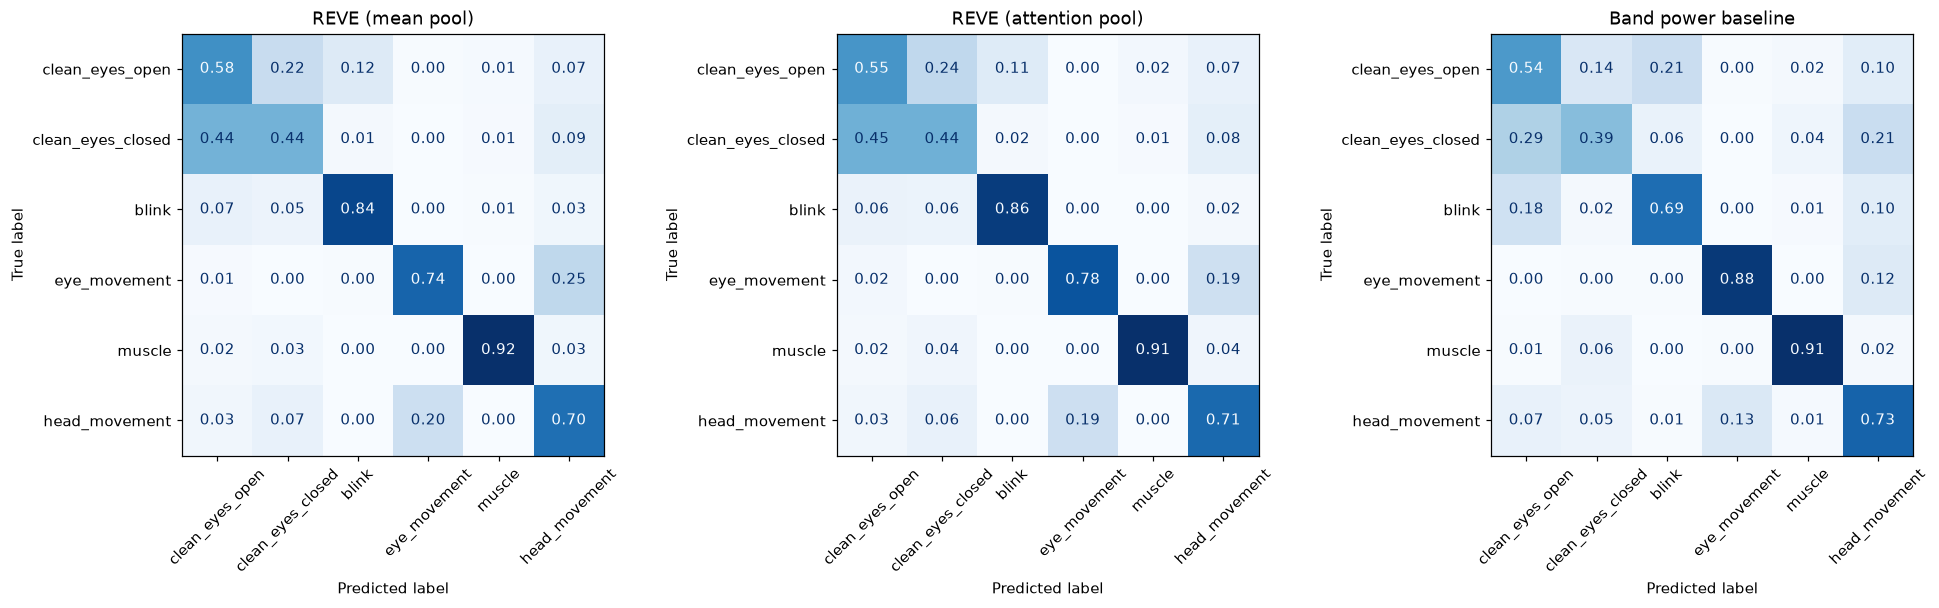

In [5]:
fig, axes = plt.subplots(1, len(preds), figsize=(6 * len(preds), 5.5))
for ax, (name, p) in zip(axes, preds.items()):
    ConfusionMatrixDisplay.from_predictions(data.label, p, labels=CLASSES, normalize="true", ax=ax,
                                            values_format=".2f", colorbar=False, cmap="Blues")
    ax.set_title(name); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()

## 4. Predictions overlaid on a full run
Train on all *other* subjects, then label every window of one run (including unannotated stretches).

Text(0.5, 1.0, 'sub-1 run-01: ground truth vs held-out-subject prediction')

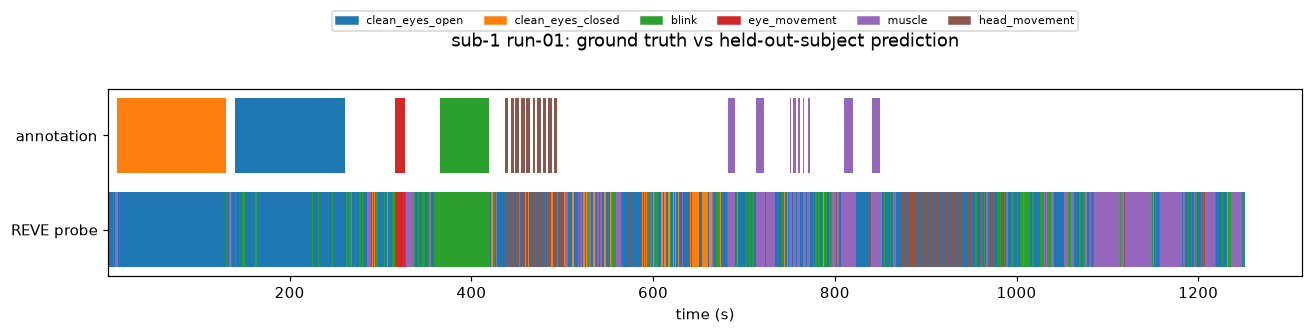

In [6]:
FEATURE = "reve_mean"
SUB, RUN = data.subject.unique()[0], 1
train = data[data.subject != SUB]
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=0.1, class_weight="balanced"))
clf.fit(np.stack(train[FEATURE]), train.label)
run_w = windows[(windows.subject == SUB) & (windows.run == RUN)]
run_pred = clf.predict(np.stack(run_w[FEATURE]))

fig, ax = plt.subplots(figsize=(14, 2.2))
for row, labels in [(1, run_w.label.values), (0, run_pred)]:
    for s, l in zip(run_w.start, labels):
        if l in COLORS:
            ax.barh(row, 1, left=s + 0.5, color=COLORS[l], height=0.8)
ax.set_yticks([0, 1], ["REVE probe", "annotation"]); ax.set_xlabel("time (s)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS.values()], labels=CLASSES,
          ncol=6, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, 1.45))
ax.set_title(f"sub-{SUB} run-{RUN:02d}: ground truth vs held-out-subject prediction", pad=28)

Text(0.0, 1.0, 'shading = annotation, bottom strip = REVE probe prediction')

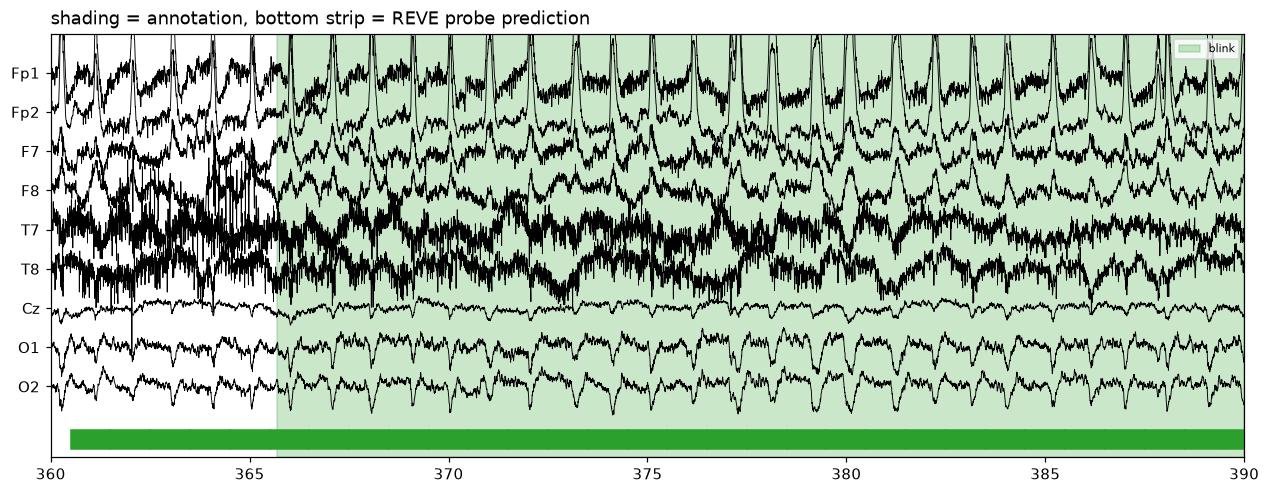

In [7]:
# Zoom: EEG with annotation shading, and the probe's per-window prediction along the bottom
T0, DUR = 360, 30
raw = reve.preprocess(pm.load_raw(SUB, RUN)); events = pm.load_annotations(SUB, RUN)
fig, ax = plt.subplots(figsize=(14, 5))
plot_snippet(raw, T0, DUR, events, ax)
in_view = (run_w.start.values >= T0) & (run_w.start.values < T0 + DUR)
for s, l in zip(run_w.start.values[in_view], run_pred[in_view]):
    ax.add_patch(plt.Rectangle((s + 0.5, -9.6 * 80), 1, 40, color=COLORS[l]))
ax.set_ylim(-9.8 * 80, 80); ax.set_title("shading = annotation, bottom strip = REVE probe prediction", loc="left")

## 5. (Nice to have) Embedding geometry
If points cluster by **subject** more than by **label**, the probe may be leaning on identity, not physiology (see the 2026 *Identity Trap* audit).

Text(0.5, 1.0, 'REVE PCA, by subject')

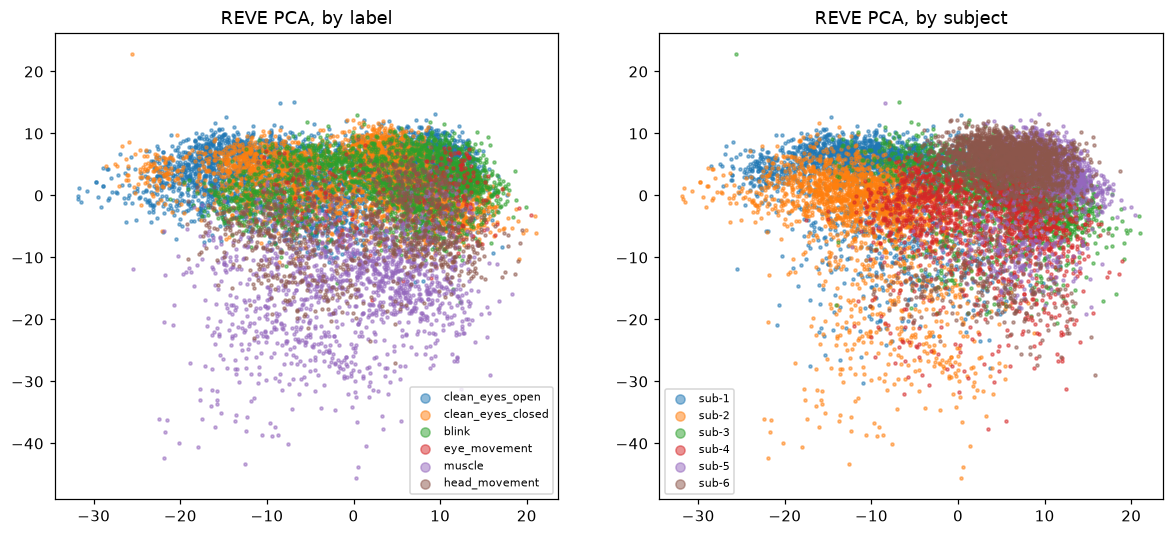

In [8]:
X = StandardScaler().fit_transform(np.stack(data.reve_mean))
Z = PCA(2).fit_transform(X)
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
for l in CLASSES:
    m = data.label == l
    axes[0].scatter(*Z[m].T, s=4, alpha=0.5, color=COLORS[l], label=l)
axes[0].legend(markerscale=3, fontsize=7); axes[0].set_title("REVE PCA, by label")
for s in sorted(data.subject.unique()):
    m = data.subject == s
    axes[1].scatter(*Z[m].T, s=4, alpha=0.5, label=f"sub-{s}")
axes[1].legend(markerscale=3, fontsize=7); axes[1].set_title("REVE PCA, by subject")

## Notes
Record findings in `README.md` (this folder) under *Log*.